In [1]:
import torch, torchvision, sklearn
print(torch.__version__, torchvision.__version__)

2.14.1+cpu 0.29.1+cpu


In [2]:
from pathlib import Path
import json, random
import numpy as np
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cpu"
DATA_DIR = Path("data/wikiart_subset")
IMAGE_SIZE = 64
BATCH_SIZE = 128

# 1. Load every image once into one tensor
ds = datasets.ImageFolder(DATA_DIR, transform=transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()]))
CLASSES = ds.classes
X_all = torch.stack([img for img, _ in ds])   # (N, 3, 64, 64), pixels in [0, 1]
y_all = torch.tensor(ds.targets)               # (N,), int64
y_np = y_all.numpy()

# 2. Stratified split 70 / 15 / 15
idx = np.arange(len(y_np))
train_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y_np, random_state=SEED)
val_idx, test_idx = train_test_split(tmp_idx, test_size=0.50, stratify=y_np[tmp_idx], random_state=SEED)
train_idx, val_idx, test_idx = map(torch.from_numpy, (train_idx, val_idx, test_idx))

# 3. Standardise with the TRAINING mean and std only
mean = X_all[train_idx].mean().item()
std = X_all[train_idx].std().item()
X = (X_all - mean) / std

# 4. DataLoaders
train_loader = DataLoader(TensorDataset(X[train_idx], y_all[train_idx]), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(X[val_idx],   y_all[val_idx]),   batch_size=1000)
test_loader  = DataLoader(TensorDataset(X[test_idx],  y_all[test_idx]),  batch_size=1000)

# Save the split so the group tests on the same images
Path("outputs").mkdir(exist_ok=True)
Path("outputs/split.json").write_text(json.dumps(
    {"train": train_idx.tolist(), "val": val_idx.tolist(), "test": test_idx.tolist()}))

print("classes:", CLASSES)
print(f"mean {mean:.4f}, std {std:.4f}")
for name, ids in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    print(f"{name:5s} {len(ids):4d} | per class {np.bincount(y_np[ids.numpy()])}")

classes: ['Baroque', 'Cubism', 'Impressionism', 'Pop_Art', 'Ukiyo_e']
mean 0.4921, std 0.2608
train  350 | per class [70 70 70 70 70]
val     75 | per class [15 15 15 15 15]
test    75 | per class [15 15 15 15 15]


In [3]:
from torchvision.models import resnet18, ResNet18_Weights
import time

# Pretrained ResNet-18, last layer removed: it now outputs 512 features per image
backbone = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)   # downloads ~45 MB the first time
backbone.fc = nn.Identity()
backbone.eval()
for p in backbone.parameters():
    p.requires_grad = False   # frozen: no weight of the backbone is trained

# ResNet expects 224x224 images normalised with the ImageNet mean/std (not our own standardisation)
resnet_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
ds_r = datasets.ImageFolder(DATA_DIR, transform=resnet_tf)
assert ds_r.targets == ds.targets, "same image order as cell 1, so split.json still applies"

# Extract the features once
feats = []
t0 = time.perf_counter()
with torch.no_grad():
    for xb, _ in DataLoader(ds_r, batch_size=32):
        feats.append(backbone(xb))
elapsed = time.perf_counter() - t0
F_all = torch.cat(feats)   # (500, 512)

print("features:", tuple(F_all.shape))
print(f"CPU time: {1000 * elapsed / len(F_all):.1f} ms per image (batches of 32)")

features: (500, 512)
CPU time: 11.4 ms per image (batches of 32)


In [4]:
# Course helpers (TP04/TP05): training loop and evaluation

def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb)
            total_loss += loss_fn(logits, yb).item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return total_loss / total, correct / total


def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    running, total = 0.0, 0
    for xb, yb in loader:
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item() * len(yb)
        total += len(yb)
    return running / total


def fit(model, train_loader, val_loader, loss_fn, optimizer, n_epochs, verbose=True):
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(n_epochs):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if verbose:
            print(f"epoch {epoch + 1:2d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.3f}")
    return history

epoch  1 | train loss 1.6053 | val loss 1.3763 | val acc 0.413
epoch  2 | train loss 1.2250 | val loss 1.1527 | val acc 0.627
epoch  3 | train loss 1.0014 | val loss 0.9633 | val acc 0.720
epoch  4 | train loss 0.8410 | val loss 0.8722 | val acc 0.773
epoch  5 | train loss 0.7318 | val loss 0.7978 | val acc 0.800
epoch  6 | train loss 0.6677 | val loss 0.7629 | val acc 0.787
epoch  7 | train loss 0.5837 | val loss 0.7188 | val acc 0.800
epoch  8 | train loss 0.5310 | val loss 0.6902 | val acc 0.813
epoch  9 | train loss 0.4847 | val loss 0.6814 | val acc 0.813
epoch 10 | train loss 0.4529 | val loss 0.6551 | val acc 0.827
epoch 11 | train loss 0.4240 | val loss 0.6457 | val acc 0.853
epoch 12 | train loss 0.3961 | val loss 0.6270 | val acc 0.840
epoch 13 | train loss 0.3719 | val loss 0.6286 | val acc 0.827
epoch 14 | train loss 0.3497 | val loss 0.6104 | val acc 0.853
epoch 15 | train loss 0.3362 | val loss 0.6032 | val acc 0.827
epoch 16 | train loss 0.3167 | val loss 0.5988 | val ac

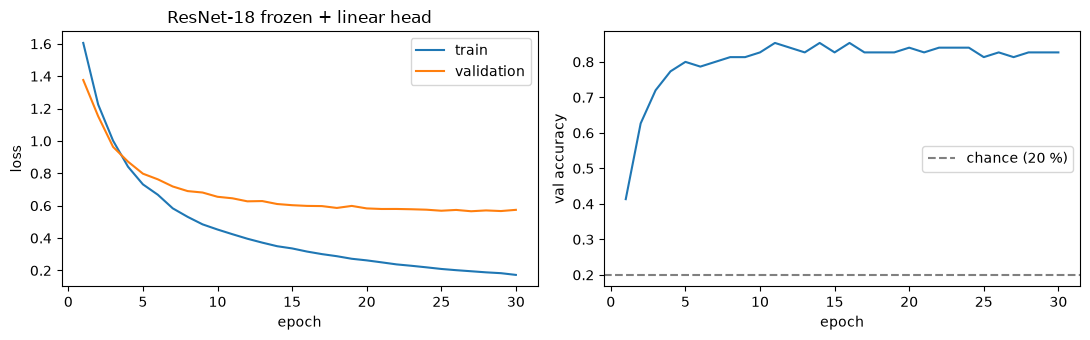

In [5]:
torch.manual_seed(SEED)
F_train, F_val, F_test = F_all[train_idx], F_all[val_idx], F_all[test_idx]
y_train, y_val, y_test = y_all[train_idx], y_all[val_idx], y_all[test_idx]

ftrain_loader = DataLoader(TensorDataset(F_train, y_train), batch_size=32, shuffle=True)
fval_loader   = DataLoader(TensorDataset(F_val, y_val), batch_size=1000)
ftest_loader  = DataLoader(TensorDataset(F_test, y_test), batch_size=1000)   # used once, at the very end

head = nn.Linear(512, len(CLASSES))   # 512 * 5 + 5 = 2565 trainable parameters
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(head.parameters(), lr=1e-3)
history_head = fit(head, ftrain_loader, fval_loader, loss_fn, optimizer, n_epochs=30)

# Training curves
epochs = range(1, len(history_head["train_loss"]) + 1)
plt.figure(figsize=(11, 3.5))
plt.subplot(1, 2, 1)
plt.plot(epochs, history_head["train_loss"], label="train")
plt.plot(epochs, history_head["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("ResNet-18 frozen + linear head")
plt.subplot(1, 2, 2)
plt.plot(epochs, history_head["val_acc"])
plt.axhline(1 / len(CLASSES), ls="--", c="grey", label="chance (20 %)")
plt.xlabel("epoch"); plt.ylabel("val accuracy"); plt.legend()
plt.tight_layout(); plt.show()

## Step 1 — Classical baselines (validation only)

Is a neural network worth it on a CPU kiosk? We compare with **logistic regression**, a classical linear model, on the same split:

- **Raw pixels**: the standardised 64×64 images, flattened. No knowledge of what images look like.
- **ResNet features**: the 512 frozen ResNet-18 features from cell 2. Same input as the linear head.

The regularisation strength `C` is chosen on the **validation set**. The test set is not used here.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

C_GRID = [0.001, 0.01, 0.1, 1, 10]   # C = inverse of regularisation strength: small C = simpler model


def pick_C(X_tr, y_tr, X_va, y_va, name):
    # Fit one logistic regression per C and keep the best on validation (ties -> smaller C)
    best = None
    for C in C_GRID:
        clf = LogisticRegression(C=C, max_iter=5000)
        clf.fit(X_tr, y_tr)
        tr_acc, va_acc = clf.score(X_tr, y_tr), clf.score(X_va, y_va)
        print(f"{name} | C={C:<6} | train acc {tr_acc:.3f} | val acc {va_acc:.3f}")
        if best is None or va_acc > best["val_acc"]:
            best = {"C": C, "model": clf, "train_acc": tr_acc, "val_acc": va_acc}
    print(f"-> chosen C={best['C']} | val acc {best['val_acc']:.3f}\n")
    return best


# 1. Raw pixels: each standardised image (cell 1) flattened into 3 * 64 * 64 = 12288 numbers
P_train, P_val = X[train_idx].flatten(1).numpy(), X[val_idx].flatten(1).numpy()
logreg_pixels = pick_C(P_train, y_train.numpy(), P_val, y_val.numpy(), "LogReg raw pixels    ")

# 2. ResNet features: standardise each of the 512 features with the TRAINING mean/std only
scaler = StandardScaler().fit(F_train.numpy())
S_train, S_val = scaler.transform(F_train.numpy()), scaler.transform(F_val.numpy())
logreg_feats = pick_C(S_train, y_train.numpy(), S_val, y_val.numpy(), "LogReg ResNet features")

LogReg raw pixels     | C=0.001  | train acc 0.920 | val acc 0.293
LogReg raw pixels     | C=0.01   | train acc 1.000 | val acc 0.307
LogReg raw pixels     | C=0.1    | train acc 1.000 | val acc 0.347
LogReg raw pixels     | C=1      | train acc 1.000 | val acc 0.320
LogReg raw pixels     | C=10     | train acc 1.000 | val acc 0.360
-> chosen C=10 | val acc 0.360

LogReg ResNet features | C=0.001  | train acc 0.920 | val acc 0.827
LogReg ResNet features | C=0.01   | train acc 0.977 | val acc 0.840
LogReg ResNet features | C=0.1    | train acc 1.000 | val acc 0.813
LogReg ResNet features | C=1      | train acc 1.000 | val acc 0.800
LogReg ResNet features | C=10     | train acc 1.000 | val acc 0.813
-> chosen C=0.01 | val acc 0.840



In [7]:
# Validation summary so far (75 validation images: 1 image = 1.3 percentage points)
n_val = len(val_idx)
val_results = {
    "LogReg on raw pixels": logreg_pixels["val_acc"],
    "LogReg on ResNet-18 features": logreg_feats["val_acc"],
    "ResNet-18 frozen + linear head (epoch 30)": history_head["val_acc"][-1],
}
print(f"{'chance':45s} val acc {1 / len(CLASSES):.3f}")
for name, acc in val_results.items():
    print(f"{name:45s} val acc {acc:.3f}  ({round(acc * n_val)}/{n_val} images)")

chance                                        val acc 0.200
LogReg on raw pixels                          val acc 0.360  (27/75 images)
LogReg on ResNet-18 features                  val acc 0.840  (63/75 images)
ResNet-18 frozen + linear head (epoch 30)     val acc 0.827  (62/75 images)


## Step 1b — Feed-forward network (FNN) on raw pixels (validation only)

The brief asks for a feed-forward network built from PyTorch primitives. It gets the **same input** as the raw-pixel logistic regression of Step 1: the standardised 64×64 images of cell 1, flattened into 12,288 numbers.

- Model: 12,288 inputs → 256 hidden ReLU units → 5 scores (3.1 million weights).
- Trained with the course `fit` helper: Adam, batch size 32, 30 epochs.
- **Early stopping, as in the course:** for each learning rate (1e-4, 3e-4, 1e-3) we keep the epoch with the lowest validation loss, then choose the learning rate with the lowest validation loss. Step 2 kept the epoch with the best validation *accuracy*; here validation accuracy jumps from epoch to epoch (up to 32/75 at a single epoch, see the output below), so we use the course rule, which is more conservative. The best-accuracy epoch is printed too.
- Added after Step 5 and **not evaluated on the test set**: the test set measures the chosen model only.

In [8]:
import copy

# Feed-forward network (FNN): flattened image -> one hidden layer of ReLU units -> one score per style
def make_fnn(hidden=256):
    return nn.Sequential(
        nn.Flatten(),                                   # (N, 3, 64, 64) -> (N, 12288)
        nn.Linear(3 * IMAGE_SIZE * IMAGE_SIZE, hidden),
        nn.ReLU(),
        nn.Linear(hidden, len(CLASSES)),                # raw scores (logits): CrossEntropyLoss applies softmax
    )


def train_fnn(lr, hidden=256, n_epochs=30, batch_size=32, X_in=X, seed=SEED):
    # Train one FNN with the course fit helper, one epoch at a time
    # Early stopping as in the course: keep the epoch with the LOWEST validation loss
    torch.manual_seed(seed)
    model = make_fnn(hidden)
    tr = TensorDataset(X_in[train_idx], y_all[train_idx])
    loader = DataLoader(tr, batch_size=batch_size, shuffle=True)
    tr_eval = DataLoader(tr, batch_size=1000)
    va = DataLoader(TensorDataset(X_in[val_idx], y_all[val_idx]), batch_size=1000)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best = {"val_loss": float("inf")}
    for epoch in range(1, n_epochs + 1):
        h = fit(model, loader, va, loss_fn, optimizer, n_epochs=1, verbose=False)
        hist["train_loss"] += h["train_loss"]
        hist["val_loss"] += h["val_loss"]
        hist["val_acc"] += h["val_acc"]
        hist["train_acc"].append(evaluate(model, tr_eval, loss_fn)[1])   # accuracy on train after the epoch
        if h["val_loss"][0] < best["val_loss"]:
            best = {"val_loss": h["val_loss"][0], "val_acc": h["val_acc"][0], "epoch": epoch,
                    "state": copy.deepcopy(model.state_dict())}
    model.load_state_dict(best["state"])
    return model, hist, best


loss_fn = nn.CrossEntropyLoss()
LR_GRID = [1e-4, 3e-4, 1e-3]
n_val = len(val_idx)
fnn_runs = {}
for lr in LR_GRID:
    model, hist, best = train_fnn(lr)
    fnn_runs[lr] = (model, hist, best)
    print(f"lr={lr:<6} | lowest val loss {best['val_loss']:.3f} at epoch {best['epoch']:2d}, val acc there {best['val_acc']:.3f}"
          f" ({round(best['val_acc'] * n_val)}/{n_val}) | highest val acc of any epoch {max(hist['val_acc']):.3f}"
          f" | last epoch: train acc {hist['train_acc'][-1]:.3f}, val acc {hist['val_acc'][-1]:.3f}")

# Learning rate chosen on validation: lowest validation loss
fnn_lr = min(LR_GRID, key=lambda lr: fnn_runs[lr][2]["val_loss"])
fnn, history_fnn, best_fnn = fnn_runs[fnn_lr]
n_params_fnn = sum(p.numel() for p in fnn.parameters())
print(f"\n-> chosen lr={fnn_lr} | {n_params_fnn:,} weights | kept epoch {best_fnn['epoch']}: "
      f"val loss {best_fnn['val_loss']:.3f}, val acc {best_fnn['val_acc']:.3f} ({round(best_fnn['val_acc'] * n_val)}/{n_val})")

lr=0.0001 | lowest val loss 1.576 at epoch  3, val acc there 0.360 (27/75) | highest val acc of any epoch 0.387 | last epoch: train acc 1.000, val acc 0.347
lr=0.0003 | lowest val loss 1.802 at epoch  3, val acc there 0.360 (27/75) | highest val acc of any epoch 0.427 | last epoch: train acc 0.991, val acc 0.347
lr=0.001  | lowest val loss 3.077 at epoch  6, val acc there 0.333 (25/75) | highest val acc of any epoch 0.360 | last epoch: train acc 0.971, val acc 0.320

-> chosen lr=0.0001 | 3,147,269 weights | kept epoch 3: val loss 1.576, val acc 0.360 (27/75)


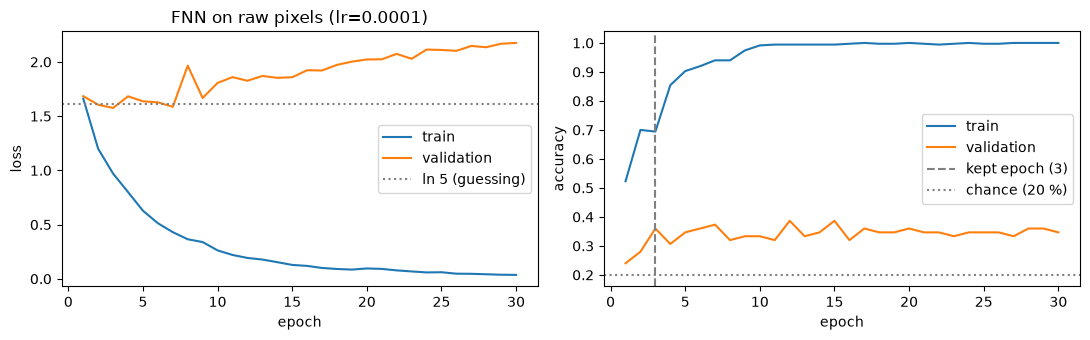

model (validation, 75 images)            val acc  correct
chance                                     0.200
LogReg on raw pixels (Step 1)              0.360    27/75
FNN on raw pixels, kept epoch 3            0.360    27/75
FNN on raw pixels, last epoch              0.347    26/75
FNN on raw pixels, best epoch (optimistic)   0.387    29/75
ResNet-18 frozen + linear head (epoch 30)   0.827    62/75

FNN: 3,147,269 weights, 12.6 MB, 0.36 ms per painting on 1 thread (model only, median)


In [9]:
import io

# Training curves of the chosen FNN: train AND validation, loss and accuracy
ep = range(1, len(history_fnn["train_loss"]) + 1)
plt.figure(figsize=(11, 3.5))
plt.subplot(1, 2, 1)
plt.plot(ep, history_fnn["train_loss"], label="train")
plt.plot(ep, history_fnn["val_loss"], label="validation")
plt.axhline(np.log(len(CLASSES)), ls=":", c="grey", label="ln 5 (guessing)")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title(f"FNN on raw pixels (lr={fnn_lr})")
plt.subplot(1, 2, 2)
plt.plot(ep, history_fnn["train_acc"], label="train")
plt.plot(ep, history_fnn["val_acc"], label="validation")
plt.axvline(best_fnn["epoch"], ls="--", c="grey", label=f"kept epoch ({best_fnn['epoch']})")
plt.axhline(1 / len(CLASSES), ls=":", c="grey", label="chance (20 %)")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.tight_layout(); plt.show()

# Save the chosen weights (outputs/ is not committed)
torch.save(fnn.state_dict(), "outputs/fnn.pt")

# CPU time of one prediction at batch size 1 on 1 thread (median of 150 runs, as in Step 4)
fnn.eval()
all_threads = torch.get_num_threads()
torch.set_num_threads(1)
times = []
with torch.inference_mode():
    for _ in range(3):
        for k in range(50):
            x1 = X[val_idx[k]].unsqueeze(0)
            t0 = time.perf_counter()
            fnn(x1).argmax(dim=1)
            times.append(1000 * (time.perf_counter() - t0))
torch.set_num_threads(all_threads)
buf = io.BytesIO(); torch.save(fnn.state_dict(), buf)

# Comparison on the same 75 validation images
print(f"{'model (validation, 75 images)':40s} {'val acc':>7s} {'correct':>8s}")
print(f"{'chance':40s} {0.2:7.3f}")
for name, acc in [("LogReg on raw pixels (Step 1)", logreg_pixels["val_acc"]),
                  (f"FNN on raw pixels, kept epoch {best_fnn['epoch']}", best_fnn["val_acc"]),
                  ("FNN on raw pixels, last epoch", history_fnn["val_acc"][-1]),
                  ("FNN on raw pixels, best epoch (optimistic)", max(history_fnn["val_acc"])),
                  ("ResNet-18 frozen + linear head (epoch 30)", history_head["val_acc"][-1])]:
    print(f"{name:40s} {acc:7.3f} {round(acc * n_val):>5d}/{n_val}")
print(f"\nFNN: {n_params_fnn:,} weights, {buf.tell() / 1e6:.1f} MB, "
      f"{np.median(times):.2f} ms per painting on 1 thread (model only, median)")

**Result.** The FNN gets **27/75** on validation (kept epoch 3), the same as logistic regression on the same pixels (27/75) and far below the models on ResNet-18 features (62–64/75).

- After epoch 3 it memorises the training images: train accuracy reaches 1.000 while the validation loss rises (Step 4b, row 5).
- It is the cheapest network (under 0.5 ms per painting on 1 thread, 12.6 MB), but hidden layers on raw pixels add nothing over a linear model here. What makes the difference is the pretrained ResNet features.

## Step 2 — Fine-tune the last ResNet block (validation only)

Frozen version: only the linear head learns (2,565 weights). Here we also retrain **`layer4`**, the last block of ResNet-18, so the features themselves can adapt to painting styles.

- Blocks 1–3 stay frozen, so their output is computed **once** and cached; only `layer4` + a new head are trained, with the course `fit` helper.
- Learning rate 1e-4 for the pretrained block (small steps, so we don't destroy what it learned on ImageNet) and 1e-3 for the new head (same as the frozen version).
- The weights from the epoch with the best validation accuracy are kept. The test set is not used.

In [10]:
import copy

# Blocks 1-3 are frozen and in eval mode, so their output never changes: compute it once for all 500 images
def frozen_trunk(x):
    b = backbone
    x = b.maxpool(b.relu(b.bn1(b.conv1(x))))
    return b.layer3(b.layer2(b.layer1(x)))

with torch.no_grad():
    H_all = torch.cat([frozen_trunk(xb) for xb, _ in DataLoader(ds_r, batch_size=32)])   # (500, 256, 14, 14)

    # Sanity check: frozen layer4 + average pooling on the cache must give back the features of cell 2
    F_check = backbone.avgpool(backbone.layer4(H_all[:16])).flatten(1)
    assert torch.allclose(F_check, F_all[:16], atol=1e-4)

print("cached layer3 output:", tuple(H_all.shape))

cached layer3 output: (500, 256, 14, 14)


trainable parameters: 8,396,293 (frozen version: 2,565)
epoch  1 | train loss 1.2143 | val loss 0.8866 | val acc 0.653
epoch  2 | train loss 0.3291 | val loss 0.5569 | val acc 0.827
epoch  3 | train loss 0.1310 | val loss 0.5542 | val acc 0.827
epoch  4 | train loss 0.0410 | val loss 0.5070 | val acc 0.827
epoch  5 | train loss 0.0220 | val loss 0.4913 | val acc 0.827
epoch  6 | train loss 0.0187 | val loss 0.4966 | val acc 0.853
epoch  7 | train loss 0.0100 | val loss 0.5082 | val acc 0.827
epoch  8 | train loss 0.0064 | val loss 0.5125 | val acc 0.853
epoch  9 | train loss 0.0070 | val loss 0.5072 | val acc 0.840
epoch 10 | train loss 0.0042 | val loss 0.5037 | val acc 0.853
epoch 11 | train loss 0.0056 | val loss 0.5097 | val acc 0.840
epoch 12 | train loss 0.0032 | val loss 0.5068 | val acc 0.840
epoch 13 | train loss 0.0035 | val loss 0.5183 | val acc 0.840
epoch 14 | train loss 0.0026 | val loss 0.5175 | val acc 0.840
epoch 15 | train loss 0.0031 | val loss 0.5189 | val acc 0.840

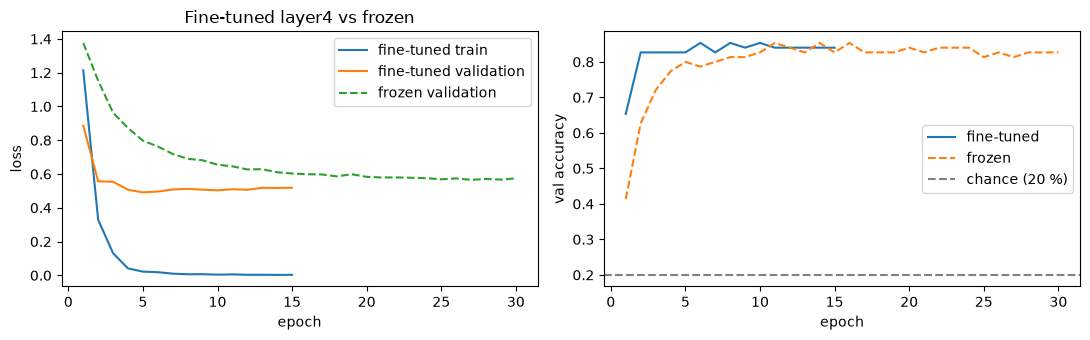

In [11]:
torch.manual_seed(SEED)

# Trainable part: a COPY of layer4 (the frozen backbone stays untouched) + a new linear head
finetuned = nn.Sequential(
    copy.deepcopy(backbone.layer4),
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(512, len(CLASSES)),
)
for p in finetuned.parameters():
    p.requires_grad = True
n_params_ft = sum(p.numel() for p in finetuned.parameters())
print(f"trainable parameters: {n_params_ft:,} (frozen version: {sum(p.numel() for p in head.parameters()):,})")

htrain_loader = DataLoader(TensorDataset(H_all[train_idx], y_train), batch_size=32, shuffle=True)
hval_loader   = DataLoader(TensorDataset(H_all[val_idx], y_val), batch_size=1000)

optimizer_ft = torch.optim.Adam([
    {"params": finetuned[0].parameters(), "lr": 1e-4},   # pretrained block: small steps
    {"params": finetuned[3].parameters(), "lr": 1e-3},   # new head: same lr as the frozen version
])

# Train one epoch at a time with the course fit helper, keeping the best weights on validation
N_EPOCHS_FT = 15
history_ft = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val_acc, best_epoch, best_state = -1.0, None, None
t0 = time.perf_counter()
for epoch in range(1, N_EPOCHS_FT + 1):
    h = fit(finetuned, htrain_loader, hval_loader, loss_fn, optimizer_ft, n_epochs=1, verbose=False)
    for k in history_ft:
        history_ft[k] += h[k]
    print(f"epoch {epoch:2d} | train loss {h['train_loss'][0]:.4f} | val loss {h['val_loss'][0]:.4f} | val acc {h['val_acc'][0]:.3f}")
    if h["val_acc"][0] > best_val_acc:
        best_val_acc, best_epoch = h["val_acc"][0], epoch
        best_state = copy.deepcopy(finetuned.state_dict())
train_time_ft = time.perf_counter() - t0
finetuned.load_state_dict(best_state)
print(f"\nbest epoch {best_epoch} (val acc {best_val_acc:.3f}) | training time {train_time_ft:.0f} s on CPU")

# Training curves: frozen vs fine-tuned
plt.figure(figsize=(11, 3.5))
plt.subplot(1, 2, 1)
plt.plot(range(1, N_EPOCHS_FT + 1), history_ft["train_loss"], label="fine-tuned train")
plt.plot(range(1, N_EPOCHS_FT + 1), history_ft["val_loss"], label="fine-tuned validation")
plt.plot(epochs, history_head["val_loss"], ls="--", label="frozen validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Fine-tuned layer4 vs frozen")
plt.subplot(1, 2, 2)
plt.plot(range(1, N_EPOCHS_FT + 1), history_ft["val_acc"], label="fine-tuned")
plt.plot(epochs, history_head["val_acc"], ls="--", label="frozen")
plt.axhline(1 / len(CLASSES), ls="--", c="grey", label="chance (20 %)")
plt.xlabel("epoch"); plt.ylabel("val accuracy"); plt.legend()
plt.tight_layout(); plt.show()

In [12]:
# Frozen vs fine-tuned on the same validation images
# "best" = best epoch chosen on validation (slightly optimistic); "last" = final epoch
train_acc_head = evaluate(head, DataLoader(TensorDataset(F_train, y_train), batch_size=1000), loss_fn)[1]
train_acc_ft = evaluate(finetuned, DataLoader(TensorDataset(H_all[train_idx], y_train), batch_size=1000), loss_fn)[1]
rows = [
    ("ResNet-18 frozen + linear head", sum(p.numel() for p in head.parameters()), train_acc_head, history_head),
    ("ResNet-18 layer4 fine-tuned + head", n_params_ft, train_acc_ft, history_ft),
]
print(f"{'model':36s} {'trainable':>10s} {'train acc':>9s} {'val acc last':>12s} {'val acc best (epoch)':>21s}")
for name, n_p, tr_acc, hist in rows:
    best = max(hist["val_acc"])
    print(f"{name:36s} {n_p:>10,} {tr_acc:>9.3f} {hist['val_acc'][-1]:>12.3f} "
          f"{best:>13.3f} ({hist['val_acc'].index(best) + 1:2d})")
print("\n(train acc: frozen head at its last epoch, fine-tuned model at its kept best epoch)")

model                                 trainable train acc val acc last  val acc best (epoch)
ResNet-18 frozen + linear head            2,565     0.980        0.827         0.853 (11)
ResNet-18 layer4 fine-tuned + head    8,396,293     1.000        0.840         0.853 ( 6)

(train acc: frozen head at its last epoch, fine-tuned model at its kept best epoch)


## Step 3 — Error analysis on validation

Which styles does the model confuse? We analyse the **frozen ResNet-18 + linear head** (weights after epoch 30, as trained in cell 4) on the 75 validation images:

- **Confusion matrix**: rows = true style, columns = predicted style; the diagonal holds the correct answers.
- **Most frequent mistake**: the largest number off the diagonal.
- **Shared errors**: do the other two ResNet-based models fail on the same paintings?
- **Misclassified paintings**, shown with the model's confidence and the artist.

The test set is still not used.

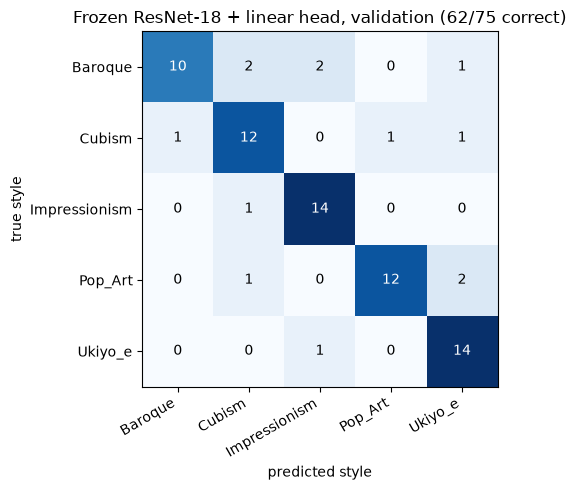

Baroque        10/15 correct (67%)
Cubism         12/15 correct (80%)
Impressionism  14/15 correct (93%)
Pop_Art        12/15 correct (80%)
Ukiyo_e        14/15 correct (93%)

most frequent mistake: 2 paintings, reached by 3 pair(s):
  Baroque predicted as Cubism
  Baroque predicted as Impressionism
  Pop_Art predicted as Ukiyo_e


In [13]:
from sklearn.metrics import confusion_matrix

# Predictions of the frozen head on the validation features
head.eval()
with torch.no_grad():
    probs_val = torch.softmax(head(F_val), dim=1)
pred_val = probs_val.argmax(dim=1)
K = len(CLASSES)
cm = confusion_matrix(y_val.numpy(), pred_val.numpy(), labels=list(range(K)))

# Confusion matrix: one hue, light = few images, dark = many
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues")
for i in range(K):
    for j in range(K):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(K), CLASSES, rotation=30, ha="right")
ax.set_yticks(range(K), CLASSES)
ax.set_xlabel("predicted style"); ax.set_ylabel("true style")
ax.set_title(f"Frozen ResNet-18 + linear head, validation ({np.trace(cm)}/{cm.sum()} correct)")
plt.tight_layout(); plt.show()

# Recall per style: share of the 15 paintings of that style that are recognised
for i, c in enumerate(CLASSES):
    print(f"{c:14s} {cm[i, i]:2d}/{cm[i].sum()} correct ({cm[i, i] / cm[i].sum():.0%})")

# Most frequent mistake = largest value off the diagonal (several pairs can tie)
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = list(zip(*np.where(off == off.max())))
print(f"\nmost frequent mistake: {off.max()} paintings, reached by {len(pairs)} pair(s):")
for i, j in pairs:
    print(f"  {CLASSES[i]} predicted as {CLASSES[j]}")

In [14]:
# Do the other ResNet-based models make the same mistakes? (same validation images)
finetuned.eval()
with torch.no_grad():
    pred_ft = finetuned(H_all[val_idx]).argmax(dim=1).numpy()
pred_lr = logreg_feats["model"].predict(S_val)

y_v = y_val.numpy()
errors = {
    "frozen + linear head": set(np.where(pred_val.numpy() != y_v)[0]),
    "LogReg on features": set(np.where(pred_lr != y_v)[0]),
    "layer4 fine-tuned": set(np.where(pred_ft != y_v)[0]),
}
for name, e in errors.items():
    print(f"{name:22s} {len(e):2d} errors")
shared = set.intersection(*errors.values())
print(f"\nmisclassified by all three models: {len(shared)} paintings")

frozen + linear head   13 errors
LogReg on features     12 errors
layer4 fine-tuned      11 errors

misclassified by all three models: 5 paintings


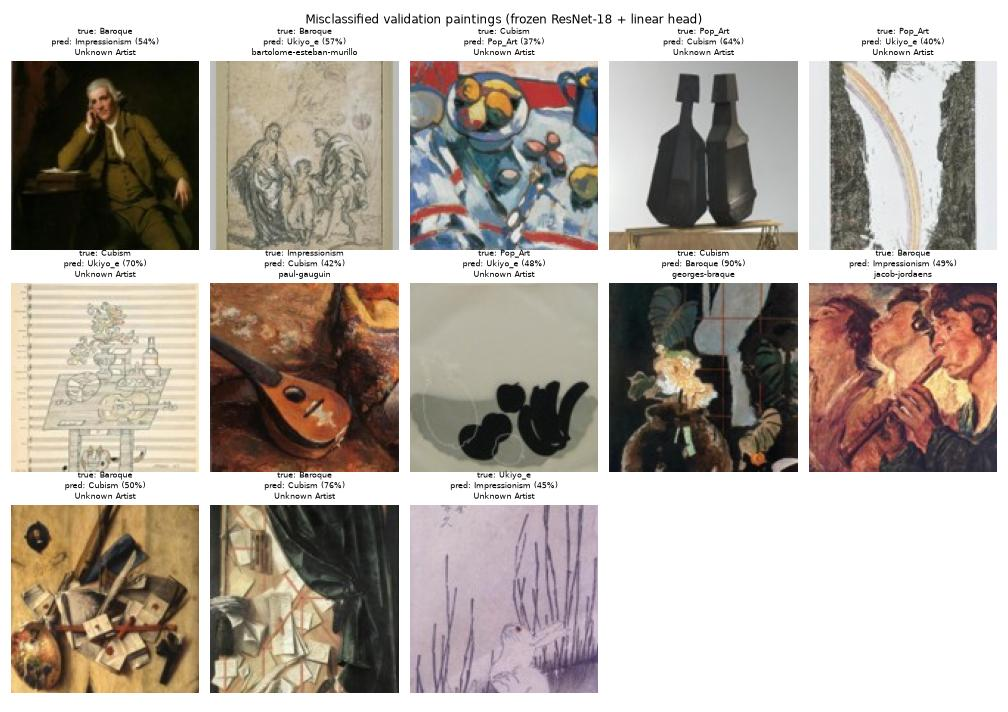

mean confidence when right: 80% | when wrong: 56%


In [15]:
import io
import pandas as pd
from PIL import Image
from IPython.display import Image as ShowImage, display

# Artist and genre of each image, from the metadata written by make_wikiart_subset.py
meta = pd.read_csv(DATA_DIR / "metadata.csv").set_index("path")

# Show every misclassified validation painting with the model's confidence
wrong = torch.where(pred_val != y_val)[0].tolist()
cols = 5
rows = (len(wrong) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(2.8 * cols, 3.3 * rows))
for ax in axes.flat:
    ax.axis("off")
for ax, k in zip(axes.flat, wrong):
    img_path = Path(ds.imgs[val_idx[k].item()][0])
    artist = meta.loc[img_path.relative_to(DATA_DIR).as_posix(), "artist"]
    ax.imshow(Image.open(img_path).convert("RGB"))
    ax.set_title(f"true: {CLASSES[y_val[k]]}\npred: {CLASSES[pred_val[k]]} ({probs_val[k].max():.0%})\n{artist}", fontsize=8)
plt.suptitle("Misclassified validation paintings (frozen ResNet-18 + linear head)")
plt.tight_layout()

# Shown as a compressed JPEG so the notebook stays small in git (as a PNG this figure is ~1.6 MB)
buf = io.BytesIO()
fig.savefig(buf, format="jpg", dpi=72, pil_kwargs={"quality": 75})
plt.close(fig)
display(ShowImage(buf.getvalue()))

# Confidence: is the model less sure when it is wrong?
conf = probs_val.max(dim=1).values
right = pred_val == y_val
print(f"mean confidence when right: {conf[right].mean():.0%} | when wrong: {conf[~right].mean():.0%}")

## Step 4 — Kiosk cost: CPU time per painting and model size

A kiosk classifies **one painting at a time**, so we time each model at **batch size 1** on CPU:

- **Preprocessing**: open the image file and turn it into the model's input tensor.
- **Model**: from input tensor to predicted style; median and 95th percentile over 150 runs (50 validation images × 3), after a warm-up.
- Measured with all CPU threads of this laptop and with **1 thread**, closer to a modest kiosk CPU.
- **Size**: number of weights and size in MB when the weights are saved.

In [16]:
import io, pickle

# 50 validation images, already preprocessed for each kind of model (timing does not use the test set)
some_val = [val_idx[k].item() for k in range(50)]
x224 = [ds_r[i][0].unsqueeze(0) for i in some_val]   # ResNet input: 1 x 3 x 224 x 224
x64 = [X[i].unsqueeze(0) for i in some_val]           # raw-pixel input: 1 x 3 x 64 x 64, standardised

# Each pipeline goes from one input tensor to one predicted style
head.eval(); finetuned.eval(); backbone.eval()
pipelines = {
    "LogReg on raw pixels":         (lambda x: logreg_pixels["model"].predict(x.flatten(1).numpy()), x64),
    "LogReg on ResNet-18 features": (lambda x: logreg_feats["model"].predict(scaler.transform(backbone(x).numpy())), x224),
    "ResNet-18 frozen + linear head": (lambda x: head(backbone(x)).argmax(dim=1), x224),
    "ResNet-18 layer4 fine-tuned":  (lambda x: finetuned(frozen_trunk(x)).argmax(dim=1), x224),
}


def time_ms(fn, inputs, repeats=3):
    # Median and 95th percentile time of one prediction, in milliseconds
    with torch.inference_mode():
        for x in inputs[:5]:
            fn(x)                                    # warm-up: first calls are slower
        times = []
        for _ in range(repeats):
            for x in inputs:
                t0 = time.perf_counter()
                fn(x)
                times.append(1000 * (time.perf_counter() - t0))
    return np.median(times), np.percentile(times, 95)


# Preprocessing, from the image file on disk to the input tensor
paths = [ds.imgs[i][0] for i in some_val]
pre_resnet = lambda p: resnet_tf(Image.open(p).convert("RGB")).unsqueeze(0)
pre_pixels = lambda p: ((ds.transform(Image.open(p).convert("RGB")) - mean) / std).unsqueeze(0)

default_threads = torch.get_num_threads()
timings = {}
for n_threads in [default_threads, 1]:
    torch.set_num_threads(n_threads)
    timings[n_threads] = {name: time_ms(fn, inputs) for name, (fn, inputs) in pipelines.items()}
    timings[n_threads]["preprocessing (ResNet, 224x224)"] = time_ms(pre_resnet, paths)
    timings[n_threads]["preprocessing (raw pixels, 64x64)"] = time_ms(pre_pixels, paths)
torch.set_num_threads(default_threads)

print(f"{'ms per painting (batch size 1)':34s} {f'{default_threads} threads: median / p95':>26s} {'1 thread: median / p95':>24s}")
for name in timings[1]:
    (m_all, p_all), (m_1, p_1) = timings[default_threads][name], timings[1][name]
    print(f"{name:34s} {m_all:15.2f} / {p_all:6.2f} {m_1:15.2f} / {p_1:6.2f}")

ms per painting (batch size 1)       16 threads: median / p95   1 thread: median / p95
LogReg on raw pixels                          0.29 /   0.38            0.17 /   0.24
LogReg on ResNet-18 features                 14.85 /  16.96           52.07 /  59.98
ResNet-18 frozen + linear head               14.53 /  16.65           52.49 /  58.38
ResNet-18 layer4 fine-tuned                  14.51 /  16.81           49.82 /  57.06
preprocessing (ResNet, 224x224)               1.56 /   2.12            1.10 /   1.52
preprocessing (raw pixels, 64x64)             0.71 /   1.20            0.47 /   0.55


In [17]:
# Model size: number of weights and MB once saved (in memory only, no file is written)
def n_weights(*modules):
    return sum(p.numel() for m in modules for p in m.parameters())

def torch_mb(*modules):
    buf = io.BytesIO()
    torch.save([m.state_dict() for m in modules], buf)
    return buf.tell() / 1e6

def pickle_mb(*objects):
    return len(pickle.dumps(objects)) / 1e6

trunk = [backbone.conv1, backbone.bn1, backbone.layer1, backbone.layer2, backbone.layer3]
sizes = {
    "LogReg on raw pixels": (logreg_pixels["model"].coef_.size + logreg_pixels["model"].intercept_.size,
                             pickle_mb(logreg_pixels["model"])),
    "LogReg on ResNet-18 features": (n_weights(backbone) + logreg_feats["model"].coef_.size + logreg_feats["model"].intercept_.size,
                                     torch_mb(backbone) + pickle_mb(scaler, logreg_feats["model"])),
    "ResNet-18 frozen + linear head": (n_weights(backbone, head), torch_mb(backbone, head)),
    "ResNet-18 layer4 fine-tuned": (n_weights(*trunk, finetuned), torch_mb(*trunk, finetuned)),
}

val_acc = {
    "LogReg on raw pixels": logreg_pixels["val_acc"],
    "LogReg on ResNet-18 features": logreg_feats["val_acc"],
    "ResNet-18 frozen + linear head": history_head["val_acc"][-1],
    "ResNet-18 layer4 fine-tuned": best_val_acc,
}

# Kiosk trade-off: accuracy vs cost (1-thread time = model + its preprocessing)
print(f"{'model':32s} {'val acc':>7s} {'weights':>12s} {'size MB':>8s} {'ms/painting, 1 thread':>22s}")
for name in pipelines:
    pre = "preprocessing (raw pixels, 64x64)" if name == "LogReg on raw pixels" else "preprocessing (ResNet, 224x224)"
    total_1 = timings[1][name][0] + timings[1][pre][0]
    n_w, mb = sizes[name]
    print(f"{name:32s} {val_acc[name]:7.3f} {n_w:12,} {mb:8.2f} {total_1:22.1f}")

model                            val acc      weights  size MB  ms/painting, 1 thread
LogReg on raw pixels               0.360       61,445     0.25                    0.6
LogReg on ResNet-18 features       0.840   11,179,077    44.81                   53.2
ResNet-18 frozen + linear head     0.827   11,179,077    44.79                   53.6
ResNet-18 layer4 fine-tuned        0.853   11,179,077    44.79                   50.9


## Step 4b — Failure diagnosis: symptom → likely cause → fix (validation only)

We provoke each failure from the course list on purpose with the Step 1b FNN, then change **one setting** as the fix. Every run uses training and validation images only; each takes a few seconds on CPU. Row 2 re-creates Hoang's FNN from `AI_Museum_Guide.ipynb` (main), whose loss stayed near ln 5 in his notebook (train loss 1.60–1.66 from epoch 3 to 10, on his own split).

| Symptom | What we saw | Likely cause | Fix (one change) | After the fix |
|---|---|---|---|---|
| Loss becomes `nan` | SGD, lr = 1.0: loss 1.9e22 after epoch 1, then `nan` | Learning rate too large: each step overshoots and the weights blow up | lr = 0.01 | Loss 1.59 → 0.94 in 5 epochs |
| Loss flat at ln 5 = 1.609 | Hoang's FNN on pixels in [0, 1]: train loss 1.585–1.665 from epoch 3 to 12 | 91 % of the first-layer and 95 % of the second-layer ReLU units are dead (output 0 for every training image), so almost no gradient flows | Standardise the inputs with the training mean/std (cell 1) | Train loss 2.38 → 0.70; dead units 0 % / 12 %. Validation accuracy unchanged (0.347): it now learns, but overfits |
| Underfitting | 1 hidden unit: train accuracy 0.229, validation 0.187 | Model too small to separate 5 styles | 256 hidden units | Train accuracy 1.000 |
| Noisy loss | Batch size 1: in the 2nd epoch the loss of each step varies with std 2.09, up to 18.4 | One image per step gives a very noisy gradient | Batch size 32 | Std 0.17, max 1.8 |
| Overfitting | Step 1b FNN: train loss 1.66 → 0.04 while validation loss rises from 1.58 (epoch 3) to 2.18 (epoch 30). Also seen in Step 2 (fine-tuned layer4: train loss 0.003, validation loss 0.491 at epoch 5 → 0.519) and Step 1 (logistic regression on pixels: train 1.000, validation 0.360) | 3.1 million weights for 350 training images: the model memorises them | Early stopping at the lowest validation loss (keeps epoch 3) | Validation accuracy 0.360 instead of 0.347. The real fix is better features: ResNet-18 features reach 62/75 |

ln 5 = 1.609

1. nan     | SGD lr=1.0 : train loss per epoch ['1.89e+22', 'nan', 'nan', 'nan', 'nan']
           | SGD lr=0.01: train loss per epoch ['1.59', '1.32', '1.19', '1.04', '0.937'] | val acc 0.333
2. flat    | pixels in [0,1]: train loss epochs 3-12 between 1.585 and 1.665 | dead units ['91%', '95%']
           | standardised   : train loss 2.375 -> 0.697 | dead units ['0%', '12%'] | val acc 0.347 vs 0.347
3. under   | 1 hidden unit  : train acc 0.229, val acc 0.187
           | 256 hidden units: train acc 1.000, val acc 0.347
4. noisy   | batch 1 : 700 steps, std of step loss (2nd epoch) 2.09, max 18.4
           | batch 32: 22 steps, std of step loss (2nd epoch) 0.17, max 1.8
5. overfit | train loss 1.662 -> 0.036; val loss lowest 1.576 at epoch 3, then 2.175 at epoch 30
           | early stopping keeps epoch 3: val acc 0.360 (last epoch 0.347)


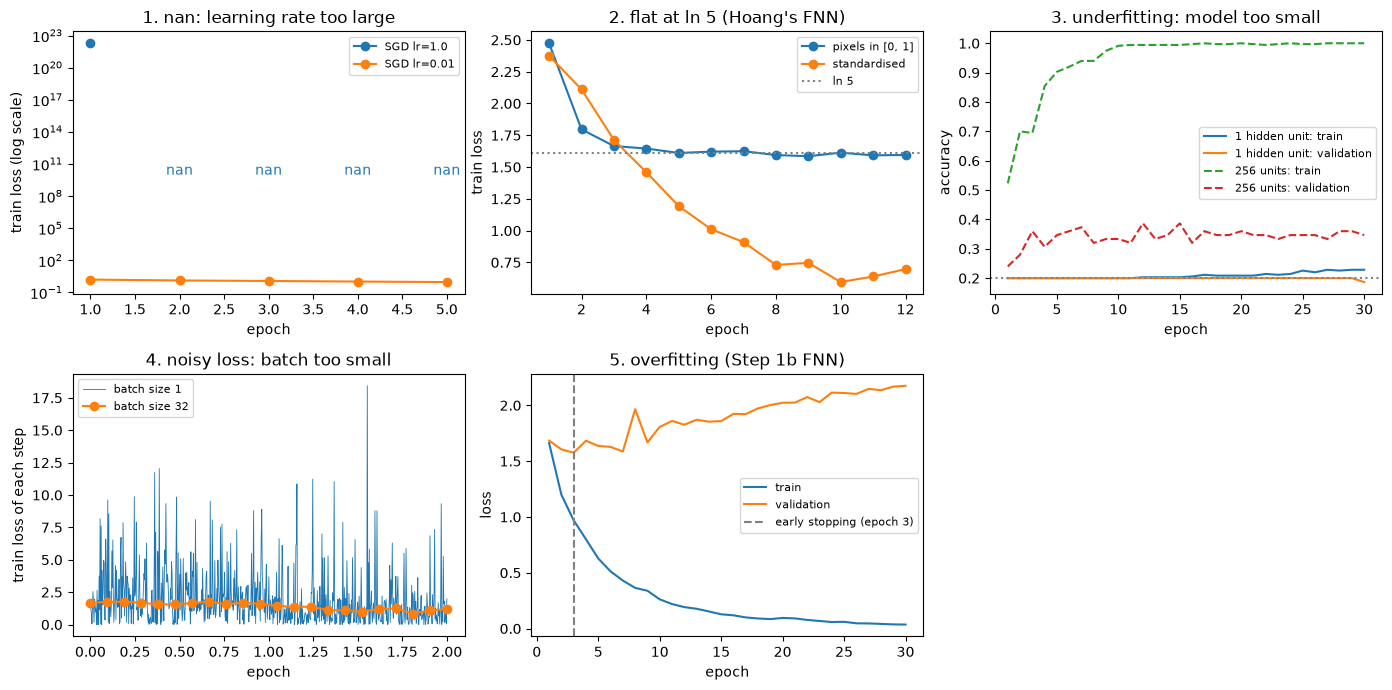

In [20]:
# Step 4b: provoke each failure on purpose, then apply ONE change as the fix (validation only)
import math

def run(make_model, X_in=X, opt=torch.optim.Adam, lr=3e-4, n_epochs=12, batch_size=32):
    # Train with the course fit helper and return the model and its history
    torch.manual_seed(SEED)
    model = make_model()
    optimizer = opt(model.parameters(), lr=lr)
    tr = DataLoader(TensorDataset(X_in[train_idx], y_all[train_idx]), batch_size=batch_size, shuffle=True)
    va = DataLoader(TensorDataset(X_in[val_idx], y_all[val_idx]), batch_size=1000)
    return model, fit(model, tr, va, loss_fn, optimizer, n_epochs, verbose=False)


def hoang_fnn():
    # Hoang's FNN from AI_Museum_Guide.ipynb (main): 512 and 128 hidden units with dropout
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(3 * IMAGE_SIZE * IMAGE_SIZE, 512), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(512, 128), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(128, len(CLASSES)),
    )


def dead_share(model, X_in):
    # Share of hidden ReLU units whose output is 0 for EVERY training image: they no longer learn
    model.eval()
    h, shares = X_in[train_idx], []
    with torch.no_grad():
        for layer in model:
            h = layer(h)
            if isinstance(layer, nn.ReLU):
                shares.append((h.max(dim=0).values == 0).float().mean().item())
    return shares


def step_losses(batch_size, n_epochs=2):
    # Training loss of EVERY step (one batch = one step), to see how noisy it is
    torch.manual_seed(SEED)
    model = make_fnn(256)
    optimizer = torch.optim.Adam(model.parameters(), lr=fnn_lr)
    loader = DataLoader(TensorDataset(X[train_idx], y_all[train_idx]), batch_size=batch_size, shuffle=True)
    losses = []
    model.train()
    for _ in range(n_epochs):
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
    return np.array(losses)


LN5 = math.log(len(CLASSES))   # loss of a model that gives 20 % to every style = "nothing learned"

# 1. nan: learning rate too large (plain SGD), fix = smaller learning rate
_, h_nan = run(make_fnn, opt=torch.optim.SGD, lr=1.0, n_epochs=5)
_, h_nan_fix = run(make_fnn, opt=torch.optim.SGD, lr=0.01, n_epochs=5)

# 2. loss flat at ln 5: Hoang's FNN on pixels in [0, 1], fix = standardise the inputs (cell 1)
m_flat, h_flat = run(hoang_fnn, X_in=X_all, lr=1e-3)
m_flat_fix, h_flat_fix = run(hoang_fnn, X_in=X, lr=1e-3)

# 3. underfitting: 1 hidden unit, fix = 256 hidden units (the Step 1b FNN)
_, h_under, _ = train_fnn(fnn_lr, hidden=1)

# 4. noisy loss: batch size 1, fix = batch size 32
noisy_1, noisy_32 = step_losses(1), step_losses(32)

# 5. overfitting: the Step 1b FNN itself (history_fnn), fix = early stopping at the lowest val loss
ep_min = int(np.argmin(history_fnn["val_loss"])) + 1

print(f"ln 5 = {LN5:.3f}\n")
print(f"1. nan     | SGD lr=1.0 : train loss per epoch {[f'{v:.3g}' for v in h_nan['train_loss']]}")
print(f"           | SGD lr=0.01: train loss per epoch {[f'{v:.3g}' for v in h_nan_fix['train_loss']]}"
      f" | val acc {h_nan_fix['val_acc'][-1]:.3f}")
print(f"2. flat    | pixels in [0,1]: train loss epochs 3-12 between {min(h_flat['train_loss'][2:]):.3f} and "
      f"{max(h_flat['train_loss'][2:]):.3f} | dead units {[f'{s:.0%}' for s in dead_share(m_flat, X_all)]}")
print(f"           | standardised   : train loss {h_flat_fix['train_loss'][0]:.3f} -> {h_flat_fix['train_loss'][-1]:.3f}"
      f" | dead units {[f'{s:.0%}' for s in dead_share(m_flat_fix, X)]}"
      f" | val acc {h_flat['val_acc'][-1]:.3f} vs {h_flat_fix['val_acc'][-1]:.3f}")
print(f"3. under   | 1 hidden unit  : train acc {h_under['train_acc'][-1]:.3f}, val acc {h_under['val_acc'][-1]:.3f}")
print(f"           | 256 hidden units: train acc {history_fnn['train_acc'][-1]:.3f}, val acc {history_fnn['val_acc'][-1]:.3f}")
print(f"4. noisy   | batch 1 : {len(noisy_1)} steps, std of step loss (2nd epoch) {noisy_1[len(noisy_1) // 2:].std():.2f}, max {noisy_1.max():.1f}")
print(f"           | batch 32: {len(noisy_32)} steps, std of step loss (2nd epoch) {noisy_32[len(noisy_32) // 2:].std():.2f}, max {noisy_32.max():.1f}")
print(f"5. overfit | train loss {history_fnn['train_loss'][0]:.3f} -> {history_fnn['train_loss'][-1]:.3f}; "
      f"val loss lowest {min(history_fnn['val_loss']):.3f} at epoch {ep_min}, then {history_fnn['val_loss'][-1]:.3f} at epoch 30")
print(f"           | early stopping keeps epoch {best_fnn['epoch']}: val acc {best_fnn['val_acc']:.3f}"
      f" (last epoch {history_fnn['val_acc'][-1]:.3f})")

# One panel per symptom: the failure and its fix
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
ax = axes[0, 0]
ax.semilogy(range(1, 6), h_nan["train_loss"], "o-", label="SGD lr=1.0")
ax.semilogy(range(1, 6), h_nan_fix["train_loss"], "o-", label="SGD lr=0.01")
for e, v in enumerate(h_nan["train_loss"], start=1):
    if math.isnan(v):
        ax.text(e, 1e10, "nan", ha="center", color="C0")   # nan cannot be drawn: write it instead
ax.set_title("1. nan: learning rate too large"); ax.set_xlabel("epoch"); ax.set_ylabel("train loss (log scale)"); ax.legend(fontsize=8)
ax = axes[0, 1]
ax.plot(range(1, 13), h_flat["train_loss"], "o-", label="pixels in [0, 1]")
ax.plot(range(1, 13), h_flat_fix["train_loss"], "o-", label="standardised")
ax.axhline(LN5, ls=":", c="grey", label="ln 5")
ax.set_title("2. flat at ln 5 (Hoang's FNN)"); ax.set_xlabel("epoch"); ax.set_ylabel("train loss"); ax.legend(fontsize=8)
ax = axes[0, 2]
ax.plot(range(1, 31), h_under["train_acc"], label="1 hidden unit: train")
ax.plot(range(1, 31), h_under["val_acc"], label="1 hidden unit: validation")
ax.plot(range(1, 31), history_fnn["train_acc"], ls="--", label="256 units: train")
ax.plot(range(1, 31), history_fnn["val_acc"], ls="--", label="256 units: validation")
ax.axhline(0.2, ls=":", c="grey")
ax.set_title("3. underfitting: model too small"); ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.legend(fontsize=8)
ax = axes[1, 0]
ax.plot(np.linspace(0, 2, len(noisy_1)), noisy_1, lw=0.6, label="batch size 1")
ax.plot(np.linspace(0, 2, len(noisy_32)), noisy_32, "o-", label="batch size 32")
ax.set_title("4. noisy loss: batch too small"); ax.set_xlabel("epoch"); ax.set_ylabel("train loss of each step"); ax.legend(fontsize=8)
ax = axes[1, 1]
ax.plot(range(1, 31), history_fnn["train_loss"], label="train")
ax.plot(range(1, 31), history_fnn["val_loss"], label="validation")
ax.axvline(best_fnn["epoch"], ls="--", c="grey", label=f"early stopping (epoch {best_fnn['epoch']})")
ax.set_title("5. overfitting (Step 1b FNN)"); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend(fontsize=8)
axes[1, 2].axis("off")
plt.tight_layout(); plt.show()

## Step 5 — Choose the model on validation, then evaluate it on the test set ONCE

**Selection rule (fixed before looking at the test set):** with 75 validation images, 1 image = 1.3 points, so models within 1–2 images of each other are treated as tied. Among tied models, keep the simplest one built with the course tools.

- The three ResNet-based models score 62, 63 and 64/75 on validation (a tie) and cost the same (42–54 ms depending on the run, 44.8 MB, step 4).
- Raw-pixel logistic regression (27/75) is far behind.
- **Chosen: ResNet-18 frozen + linear head** — fewest trainable weights (2,565), trained with PyTorch and the course `fit` helper, no validation-picked epoch.

The other models are **not** evaluated on the test set: the test set measures the chosen model only.

In [18]:
# The chosen model: frozen ResNet-18 features + linear head, weights after epoch 30 (cell 4)
# Test set used here for the first and only time
test_loss, test_acc = evaluate(head, ftest_loader, loss_fn)
n_test = len(test_idx)
n_correct = round(test_acc * n_test)

# 95% confidence interval for the accuracy (Wilson interval): how much the result could move with another 75 images
z = 1.96
centre = (test_acc + z**2 / (2 * n_test)) / (1 + z**2 / n_test)
half = z * np.sqrt(test_acc * (1 - test_acc) / n_test + z**2 / (4 * n_test**2)) / (1 + z**2 / n_test)

print(f"chosen model: ResNet-18 frozen + linear head")
print(f"test accuracy {test_acc:.3f} ({n_correct}/{n_test}) | test loss {test_loss:.4f}")
print(f"95% interval for the accuracy: {centre - half:.3f} to {centre + half:.3f}")
print(f"validation accuracy was {history_head['val_acc'][-1]:.3f} (val loss {history_head['val_loss'][-1]:.4f})")

# Correct answers per style on the test set
with torch.no_grad():
    pred_test = head(F_test).argmax(dim=1)
cm_test = confusion_matrix(y_test.numpy(), pred_test.numpy(), labels=list(range(K)))
print()
for i, c in enumerate(CLASSES):
    print(f"{c:14s} {cm_test[i, i]:2d}/{cm_test[i].sum()} correct on test")

chosen model: ResNet-18 frozen + linear head
test accuracy 0.760 (57/75) | test loss 0.6038
95% interval for the accuracy: 0.652 to 0.842
validation accuracy was 0.827 (val loss 0.5744)

Baroque        10/15 correct on test
Cubism         11/15 correct on test
Impressionism  10/15 correct on test
Pop_Art        14/15 correct on test
Ukiyo_e        12/15 correct on test


In [19]:
# Final results table: validation for every model, test for the chosen model only
rows = []
for name in pipelines:
    pre = "preprocessing (raw pixels, 64x64)" if name == "LogReg on raw pixels" else "preprocessing (ResNet, 224x224)"
    rows.append({
        "model": name,
        "val acc": round(val_acc[name], 3),
        "val correct": f"{round(val_acc[name] * n_val)}/{n_val}",
        "test acc": round(test_acc, 3) if name == "ResNet-18 frozen + linear head" else None,
        "trainable weights": {"LogReg on raw pixels": sizes[name][0],
                              "LogReg on ResNet-18 features": logreg_feats["model"].coef_.size + logreg_feats["model"].intercept_.size,
                              "ResNet-18 frozen + linear head": n_weights(head),
                              "ResNet-18 layer4 fine-tuned": n_params_ft}[name],
        "size MB": round(sizes[name][1], 2),
        "ms/painting (1 thread)": round(timings[1][name][0] + timings[1][pre][0], 1),
    })
results = pd.DataFrame(rows).set_index("model")
results["test acc"] = results["test acc"].astype(object).where(results["test acc"].notna(), "not evaluated")
print("chance: 0.200 | fine-tuned val acc = best epoch picked on validation (last epoch: "
      f"{history_ft['val_acc'][-1]:.3f})\n")
results

chance: 0.200 | fine-tuned val acc = best epoch picked on validation (last epoch: 0.840)



,val acc,val correct,test acc,trainable weights,size MB,ms/painting (1 thread)
model,,,,,,
LogReg on raw pixels,0.360,27/75,not evaluated,61445,0.25,0.6
LogReg on ResNet-18 features,0.840,63/75,not evaluated,2565,44.81,53.2
ResNet-18 frozen + linear head,0.827,62/75,0.76,2565,44.79,53.6
ResNet-18 layer4 fine-tuned,0.853,64/75,not evaluated,8396293,44.79,50.9


## Conclusion — answer to the director

All numbers come from the cells above. Accuracies are identical between runs. CPU timings are not: two full runs on this laptop gave 42–43 ms (first run, commit 82f962c) and 51–54 ms (this run) per painting on 1 thread. The notebook was re-run top to bottom on 20 Oct; the test cell gave the identical 0.760 (57/75), and no choice was changed.

**Chosen model: pretrained ResNet-18, frozen, with a linear head.**
- Test accuracy **0.760 (57/75)**, 95% interval 0.652–0.842; chance is 0.200.
- Test is 5 images below validation (0.827, 62/75). Validation was used for every decision (C for logistic regression, the fine-tuned epoch, the model choice), so it is slightly optimistic; the test number is the honest estimate. Validation lies inside the test interval, so the drop is consistent with chance on 75 images.

**Is a neural network worth it on a CPU kiosk? Yes, as a pretrained feature extractor.**
- Without it, the best classical model (logistic regression on raw pixels) reaches only 0.360 on validation.
- A feed-forward network on the same raw pixels does no better: 27/75 on validation (Step 1b). What makes the difference is the pretrained features, not hidden layers.
- With the ResNet-18 features, the classifier on top barely matters: logistic regression 0.840, linear head 0.827, fine-tuned last block 0.853 (best epoch) — 62 to 64 of 75 validation images, a tie.
- Cost on one CPU thread of this laptop: 42–54 ms per painting including preprocessing (two runs), and 44.8 MB of weights. Fine-tuning adds 8.4M trainable weights for no measurable gain.

**Limits.**
- Small data: 75 test images, so 1 image = 1.3 points and the interval above is 19 points wide (0.652–0.842).
- Baroque is the hardest style on validation (10/15); on test it ties with Impressionism (10/15 each). 5 of the 13 validation errors are not typical paintings: 2 drawings, 1 sculpture and 2 trompe-l'œil still lifes (Step 3).
- One thread of a laptop only approximates a kiosk CPU; timing should be repeated on the real hardware.
- Training is fragile without care: Step 4b shows the failures we met or provoked (nan, flat loss at ln 5, underfitting, noisy loss, overfitting) and the fix for each.